# Modèle xG de Theo Grasso

Construction d'un modèle d'expected goals (xG) en machine learning, à partir des données gratuites StatsBomb de la Serie A 2015/2016.

Le xG mesure la qualité d'une occasion : la probabilité qu'un tir finisse au fond pour un joueur moyen face à un gardien moyen. Le modèle ne connaît aucun nom de joueur. C'est ce qui permet ensuite de comparer les buts réels au xG, pour repérer les meilleurs finisseurs.

**Plan du notebook**

Étape 1. Récupération des données StatsBomb.
Étape 2. Préparation des tirs : position, type de tir, situation de jeu, position des défenseurs et du gardien.
Étape 3. Premier coup d'œil sur les données.
Étape 4. Entraînement et comparaison des modèles.
Étape 5. xG de chaque tir et classement des finisseurs.
Étape 6. Visuels.
Étape 7. Application au Milan, saison 2025/2026 (données Understat).
Étape 8. Récupération des cinq grands championnats 2015/2016, avec les passes décisives.
Étape 9. Modèle entraîné sur les cinq championnats, avec la passe décisive.

## Installation et outils

La cellule d'installation est à lancer une seule fois sur un ordinateur. Le "!" permet de lancer une installation directement depuis le notebook.

In [1]:
# statsbombpy récupère les données gratuites de StatsBomb
# mplsoccer dessine des terrains de foot à la bonne échelle
# soccerdata récupère les données Understat (utilisé à l'étape 7)
!pip install statsbombpy mplsoccer soccerdata

In [2]:
# On importe l'outil qui gère les messages d'avertissement de Python
import warnings

# On masque uniquement le message de StatsBomb sur la version gratuite, les autres avertissements restent visibles
warnings.filterwarnings("ignore", message="credentials were not supplied")

# On importe l'outil qui permet de régler l'environnement et de vérifier si un fichier existe
import os

# On demande à soccerdata de n'afficher que les vrais problèmes (doit être lu avant son import, à l'étape 7)
os.environ["SOCCERDATA_LOGLEVEL"] = "WARNING"

# pandas sert à manipuler les tableaux de données
import pandas as pd

# numpy fait les calculs mathématiques (racine carrée, angles...)
import numpy as np

# L'outil StatsBomb, sous le petit nom "sb"
from statsbombpy import sb

# Les outils de machine learning : découpage des tirs, modèles et notes
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss

# Les outils de dessin : graphiques, terrain de foot et légende
import matplotlib.pyplot as plt
from mplsoccer import Pitch
from matplotlib.lines import Line2D

## Étape 1. Récupération des données StatsBomb

StatsBomb publie gratuitement une saison complète de Serie A : 2015/2016, soit 380 matchs. On récupère tous les tirs de la saison et on les enregistre dans un fichier, pour ne les télécharger qu'une seule fois.

In [3]:
# On récupère le tableau de toutes les compétitions et saisons gratuites
competitions = sb.competitions()

# On garde seulement la Serie A, saison 2015/2016 (il existe aussi une saison 1986/1987, qu'on écarte)
saison = competitions[(competitions["competition_name"] == "Serie A") & (competitions["season_name"] == "2015/2016")]

# On récupère les identifiants de la compétition et de la saison
comp_id = saison["competition_id"].iloc[0]
saison_id = saison["season_id"].iloc[0]

# On demande à StatsBomb la liste des matchs de cette saison
matchs = sb.matches(competition_id=comp_id, season_id=saison_id)

# On vérifie le nombre de matchs, une saison complète en compte 380
print("Nombre de matchs :", len(matchs))

Nombre de matchs : 380


In [4]:
# Nom du fichier où l'on garde tous les tirs de la saison
fichier_brut = "tirs_serie_a_2015_16.pkl"

# Si le fichier existe déjà sur le PC, on le relit directement (quelques secondes)
if os.path.exists(fichier_brut):
    brut = pd.read_pickle(fichier_brut)
# Sinon, on télécharge les tirs match par match (10 à 15 minutes)
else:
    # Liste vide qui va recevoir les tirs de chaque match
    liste_tirs = []
    # On passe sur chaque match un par un, "i" compte combien on en a fait
    for i, match_id in enumerate(matchs["match_id"]):
        # On récupère toutes les actions du match
        actions = sb.events(match_id=match_id)
        # On garde seulement les tirs, dans une copie indépendante
        tirs_match = actions[actions["type"] == "Shot"].copy()
        # On note de quel match vient chaque tir
        tirs_match["match_id"] = match_id
        # On range les tirs de ce match dans la liste
        liste_tirs.append(tirs_match)
        # Tous les 50 matchs, on affiche l'avancement
        if (i + 1) % 50 == 0:
            print(i + 1, "matchs chargés sur", len(matchs))
    # On colle tous les tirs en un seul grand tableau
    brut = pd.concat(liste_tirs, ignore_index=True)
    # On l'enregistre au format pickle, qui garde les positions [x, y] intactes
    brut.to_pickle(fichier_brut)

# On affiche le nombre total de tirs de la saison
print("Nombre total de tirs :", len(brut))

Nombre total de tirs : 9998


## Étape 2. Préparation des tirs

Le modèle ne sait pas lire une position comme [106.3, 33.1]. On transforme chaque tir en informations qui ont du sens au foot.

Le terrain StatsBomb mesure 120 de long sur 80 de large, et le but visé est toujours à droite, au point (120, 40), avec les poteaux en (120, 36) et (120, 44).

On garde uniquement les tirs dans le jeu. Les penaltys et les coups francs directs sont des situations à part, ils sont étudiés séparément à l'étape 3.

Pour la position des joueurs, StatsBomb fournit une photo de chaque tir : la position de tous les joueurs visibles au moment de la frappe. On dessine un triangle entre le tireur et les deux poteaux, la zone de tir, et on compte les défenseurs qui s'y trouvent.

In [5]:
# Fonction qui dit si un joueur (point p) est dans le triangle formé par a, b et c
def dans_triangle(p, a, b, c):
    # Petite formule qui dit de quel côté d'un bord du triangle se trouve un point (positif ou négatif)
    def cote(p1, p2, p3):
        return (p1[0] - p3[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p3[1])
    # On teste le joueur par rapport aux trois bords du triangle
    d1, d2, d3 = cote(p, a, b), cote(p, b, c), cote(p, c, a)
    # On note s'il est du côté négatif d'au moins un bord
    negatif = d1 < 0 or d2 < 0 or d3 < 0
    # Et s'il est du côté positif d'au moins un bord
    positif = d1 > 0 or d2 > 0 or d3 > 0
    # S'il est du même côté des trois bords, il est dans le triangle
    return not (negatif and positif)

# Fonction qui lit la photo d'un tir et en tire trois infos : défenseurs devant, distance du gardien, gardien hors du cadre
def lire_photo(ligne):
    # La photo : la liste des joueurs visibles au moment du tir
    photo = ligne["shot_freeze_frame"]
    # La position du tireur
    tireur = ligne["location"]
    # La position des deux poteaux
    poteau_1, poteau_2 = (120, 36), (120, 44)
    # Si le tir n'a pas de photo, on laisse les cases vides
    if not isinstance(photo, list):
        return pd.Series({"defenseurs_devant": np.nan, "gardien_distance_but": np.nan, "gardien_hors_cadre": np.nan})
    # On garde seulement les joueurs adverses
    adversaires = [j for j in photo if not j["teammate"]]
    # Parmi eux, on isole le gardien
    gardiens = [j for j in adversaires if j["position"]["name"] == "Goalkeeper"]
    # Les autres sont les joueurs de champ adverses
    defenseurs = [j for j in adversaires if j["position"]["name"] != "Goalkeeper"]
    # On compte ceux qui sont dans la zone de tir
    nb_devant = sum(dans_triangle(j["location"], tireur, poteau_1, poteau_2) for j in defenseurs)
    # Si le gardien est sur la photo
    if gardiens:
        # On prend sa position
        g = gardiens[0]["location"]
        # Sa distance au centre du but (plus c'est grand, plus il est sorti)
        dist_gardien = np.sqrt((120 - g[0])**2 + (40 - g[1])**2)
        # 1 s'il n'est pas dans la zone de tir, donc qu'il ne couvre pas le but
        hors_cadre = 0 if dans_triangle(g, tireur, poteau_1, poteau_2) else 1
    else:
        # Gardien absent de la photo : on considère qu'il est hors du cadre
        dist_gardien = np.nan
        hors_cadre = 1
    # On renvoie les trois infos
    return pd.Series({"defenseurs_devant": nb_devant, "gardien_distance_but": dist_gardien, "gardien_hors_cadre": hors_cadre})

# Fonction qui transforme une colonne StatsBomb "vrai ou vide" en 1 ou 0 (0 partout si la colonne n'existe pas)
def oui_non(tableau, nom):
    return (tableau[nom] == True).astype(int) if nom in tableau.columns else 0

In [6]:
# On garde uniquement les tirs dans le jeu, dans une copie indépendante
tirs = brut[brut["shot_type"] == "Open Play"].copy()

# On sépare la position en deux colonnes : x (longueur du terrain) et y (largeur)
tirs["x"] = tirs["location"].apply(lambda pos: pos[0])
tirs["y"] = tirs["location"].apply(lambda pos: pos[1])

# Écart entre le tireur et le centre du but
ecart_x = 120 - tirs["x"]
ecart_y = 40 - tirs["y"]

# Distance au centre du but, avec le théorème de Pythagore
tirs["distance"] = np.sqrt(ecart_x**2 + ecart_y**2)

# Angle de tir en degrés : l'ouverture entre le tireur et les deux poteaux
tirs["angle"] = np.degrees(np.arctan2(8 * ecart_x, ecart_x**2 + ecart_y**2 - 16))

# 1 si c'est une tête, 0 sinon
tirs["tete"] = (tirs["shot_body_part"] == "Head").astype(int)

# 1 si face-à-face avec le gardien, 1 si tir en première intention, 1 si le tireur est sous pression
tirs["face_a_face"] = oui_non(tirs, "shot_one_on_one")
tirs["premiere_intention"] = oui_non(tirs, "shot_first_time")
tirs["sous_pression"] = oui_non(tirs, "under_pressure")

# Type d'action ayant mené au tir, le jeu placé sert de référence
tirs["contre_attaque"] = (tirs["play_pattern"] == "From Counter").astype(int)
tirs["apres_corner"] = (tirs["play_pattern"] == "From Corner").astype(int)
tirs["apres_coup_franc"] = (tirs["play_pattern"] == "From Free Kick").astype(int)
tirs["apres_touche"] = (tirs["play_pattern"] == "From Throw In").astype(int)

# On lit la photo de chaque tir (quelques secondes)
photos = tirs.apply(lire_photo, axis=1)

# On compte les tirs sans photo
print("Tirs sans photo :", photos["defenseurs_devant"].isna().sum())

# On remplit les cases vides avec la valeur la plus courante (la médiane), pour ne perdre aucun tir
photos = photos.fillna(photos.median())

# On ajoute les trois infos de la photo au tableau des tirs
tirs = tirs.join(photos)

# 1 si le tir a fini au fond, 0 sinon : c'est la réponse que le modèle doit apprendre à prévoir
tirs["but"] = (tirs["shot_outcome"] == "Goal").astype(int)

# On garde seulement les colonnes utiles
colonnes = ["match_id", "team", "player", "x", "y", "distance", "angle", "tete",
            "face_a_face", "premiere_intention", "sous_pression",
            "contre_attaque", "apres_corner", "apres_coup_franc", "apres_touche",
            "defenseurs_devant", "gardien_distance_but", "gardien_hors_cadre",
            "but", "shot_statsbomb_xg"]
tirs = tirs[colonnes]

# On enregistre le tableau préparé
tirs.to_pickle("tirs_prepares.pkl")

# On vérifie le nombre de tirs dans le jeu et on affiche les premières lignes
print("Tirs dans le jeu :", len(tirs))
tirs.head()

Tirs sans photo : 0
Tirs dans le jeu : 9396


,match_id,team,player,x,y,distance,angle,tete,face_a_face,premiere_intention,sous_pression,contre_attaque,apres_corner,apres_coup_franc,apres_touche,defenseurs_devant,gardien_distance_but,gardien_hors_cadre,but,shot_statsbomb_xg
0,3879608,Hellas Verona,Giampaolo Pazzini,106.3,33.1,15.339492,26.554600,1,0,0,0,0,0,0,0,0.0,2.555386,0.0,0,0.036725
1,3879608,Bologna,Mattia Destro,86.6,44.5,33.701780,13.420509,0,0,0,1,0,0,0,0,0.0,1.802776,0.0,0,0.021707
2,3879608,Bologna,Emanuele Giaccherini,108.4,32.7,13.705838,28.369304,0,0,1,0,0,0,0,0,0.0,2.420744,0.0,1,0.096531
3,3879608,Hellas Verona,Giampaolo Pazzini,95.7,34.8,24.850151,17.909582,0,0,0,0,0,0,0,0,0.0,3.104835,0.0,0,0.046731
4,3879608,Bologna,Mattia Destro,102.8,38.3,17.283807,25.951418,0,0,1,0,0,0,0,0,0.0,2.418677,0.0,0,0.082125


## Étape 3. Premier coup d'œil sur les données

Avant tout modèle, un simple tableau par tranches de distance donne déjà un premier xG fait main.

In [7]:
# Pourcentage de tirs qui finissent en but sur toute la saison
print("Taux de but global :", round(tirs["but"].mean() * 100, 1), "%")

# On range les tirs par tranches de distance
tranches = pd.cut(tirs["distance"], bins=[0, 6, 12, 18, 24, 30, 120])

# Pour chaque tranche : nombre de tirs et pourcentage de buts
tirs.groupby(tranches, observed=True)["but"].agg(["count", "mean"])

Taux de but global : 8.8 %


,count,mean
distance,,
"(0, 6]",223,0.497758
"(6, 12]",1799,0.178988
"(12, 18]",2053,0.113005
"(18, 24]",2107,0.047461
"(24, 30]",2008,0.021414
"(30, 120]",1206,0.013267


**Lecture.** Environ un tir sur onze finit au fond (8,8 %). À moins de 6 mètres, c'est une chance sur deux. Au-delà de 24 mètres, on tombe à 2 %.

Les penaltys sont écartés du modèle car c'est toujours la même situation. On leur donne une valeur fixe, mesurée ci-dessous. Dans les classements de joueurs, on utilise le xG hors penaltys (npxG en anglais), pour ne pas avantager les tireurs de penaltys.

In [8]:
# On garde seulement les penaltys
penaltys = brut[brut["shot_type"] == "Penalty"]

# Nombre de penaltys tirés dans la saison
print("Penaltys tirés :", len(penaltys))

# Pourcentage de penaltys réellement transformés
print("Taux de réussite réel :", round((penaltys["shot_outcome"] == "Goal").mean() * 100, 1), "%")

# Valeur de xG que StatsBomb donne aux penaltys
print("xG StatsBomb des penaltys :", penaltys["shot_statsbomb_xg"].round(3).unique())

Penaltys tirés : 121
Taux de réussite réel : 76.9 %
xG StatsBomb des penaltys : [0.784]


## Étape 4. Entraînement et comparaison des modèles

On utilise une régression logistique : le modèle donne un poids à chaque info, puis les combine pour sortir une probabilité entre 0 et 1.

Règle d'or : on cache 25 % des tirs pendant l'apprentissage, puis on teste le modèle dessus. Comme un élève interrogé sur des exercices jamais vus, sinon il pourrait apprendre par cœur.

Trois notes pour comparer les modèles. Total xG : il doit être proche du nombre de vrais buts. AUC : capacité à donner un xG plus haut aux tirs qui finissent en but (0,5 = hasard, 1 = parfait). Erreur (log loss) : plus c'est bas, mieux c'est.

On compare trois versions de plus en plus riches, un modèle plus puissant (gradient boosting) et le xG officiel StatsBomb.

In [9]:
# Version 1 : seulement la position et la tête
infos_v1 = ["distance", "angle", "tete"]

# Version 2 : on ajoute le type de tir et la situation de jeu
infos_v2 = infos_v1 + ["face_a_face", "premiere_intention", "sous_pression",
                       "contre_attaque", "apres_corner", "apres_coup_franc", "apres_touche"]

# Version 3 : on ajoute les infos de la photo (défenseurs et gardien)
infos_v3 = infos_v2 + ["defenseurs_devant", "gardien_distance_but", "gardien_hors_cadre"]

# 75 % des tirs pour apprendre, 25 % pour tester
# random_state=42 fixe le tirage au sort, stratify garde la même proportion de buts dans les deux groupes
app, test = train_test_split(tirs, test_size=0.25, random_state=42, stratify=tirs["but"])

# On entraîne les trois régressions logistiques ; max_iter=1000 leur laisse assez d'essais pour bien apprendre
modele_v1 = LogisticRegression(max_iter=1000).fit(app[infos_v1], app["but"])
modele_v2 = LogisticRegression(max_iter=1000).fit(app[infos_v2], app["but"])
modele_v3 = LogisticRegression(max_iter=1000).fit(app[infos_v3], app["but"])

# Gradient boosting : des centaines de petits arbres de questions, avec des réglages prudents
modele_gb = HistGradientBoostingClassifier(
    learning_rate=0.05,     # chaque arbre corrige un petit peu à la fois
    max_iter=300,           # au maximum 300 arbres
    max_leaf_nodes=15,      # chaque arbre reste petit
    min_samples_leaf=50,    # chaque conclusion s'appuie sur au moins 50 tirs
    early_stopping=True,    # il s'arrête quand il ne progresse plus
    random_state=42,        # même résultat à chaque lancement
).fit(app[infos_v3], app["but"])

# xG des tirs du test pour chaque modèle, plus le xG officiel StatsBomb
xg = {
    "Theo v1 (3 infos)": modele_v1.predict_proba(test[infos_v1])[:, 1],
    "Theo v2 (10 infos)": modele_v2.predict_proba(test[infos_v2])[:, 1],
    "Theo v3 (13 infos)": modele_v3.predict_proba(test[infos_v3])[:, 1],
    "Theo gradient boosting": modele_gb.predict_proba(test[infos_v3])[:, 1],
    "StatsBomb": test["shot_statsbomb_xg"].values,
}

# Tableau de comparaison
resultats = pd.DataFrame({
    nom: {"Total xG": v.sum(), "AUC": roc_auc_score(test["but"], v), "Erreur": log_loss(test["but"], v)}
    for nom, v in xg.items()
}).T.round(3)

# Nombre de vrais buts dans le test, puis le tableau
print("Vrais buts :", test["but"].sum())
resultats

Vrais buts : 206


,Total xG,AUC,Erreur
Theo v1 (3 infos),197.458,0.802,0.247
Theo v2 (10 infos),195.195,0.807,0.243
Theo v3 (13 infos),191.901,0.827,0.235
Theo gradient boosting,193.646,0.825,0.235
StatsBomb,192.903,0.849,0.226


In [10]:
# Poids du modèle v3, du plus positif au plus négatif
# Attention : distance, angle et distance du gardien s'appliquent à chaque mètre ou degré, les autres sont des 0 ou 1
pd.Series(modele_v3.coef_[0], index=infos_v3).sort_values(ascending=False).round(3)

face_a_face             0.342
apres_coup_franc        0.186
contre_attaque          0.157
gardien_hors_cadre      0.154
gardien_distance_but    0.107
angle                   0.045
sous_pression           0.028
premiere_intention      0.012
apres_touche            0.004
distance               -0.066
apres_corner           -0.265
defenseurs_devant      -0.483
tete                   -1.154
dtype: float64

**Lecture des résultats.**

Le modèle v1, avec 3 infos, atteint déjà 0,802 d'AUC. La v2 progresse peu (0,807), car la position du tir contenait déjà l'essentiel. La v3, avec la photo des joueurs, fait le plus gros bond (0,827), proche de StatsBomb (0,849).

Le gradient boosting ne fait pas mieux (0,825). Avec environ 7 000 tirs d'apprentissage, il n'a pas assez de données pour trouver des combinaisons nouvelles. On garde donc la régression logistique v3, qui a aussi l'avantage d'être explicable à un coach.

Ce que disent les poids. Chaque défenseur dans la zone de tir fait baisser les chances d'environ 40 %. Une tête divise les chances par environ 3. Chaque mètre où le gardien est sorti augmente les chances d'environ 10 %. Le face-à-face reste positif, mais son poids baisse par rapport à la v2, car il partage l'explication avec le nombre de défenseurs devant.

## Étape 5. xG de chaque tir et classement des finisseurs

Pour classer les joueurs, il faut le xG de tous les tirs. Pour qu'il soit honnête, on coupe les tirs en 5 groupes, et le xG de chaque groupe est calculé par un modèle entraîné sur les 4 autres. Aucun tir n'est noté par un modèle qui l'a déjà vu.

Buts moins xG : positif, le joueur marque plus que ses occasions ne le laissaient prévoir. Sur une seule saison la chance compte beaucoup, il faut donc rester prudent dans les conclusions.

In [11]:
# Chaque groupe de tirs reçoit le xG d'un modèle v3 entraîné sur les 4 autres groupes
tirs["xg_theo"] = cross_val_predict(
    LogisticRegression(max_iter=1000),   # le modèle retenu
    tirs[infos_v3],                      # les 13 infos de chaque tir
    tirs["but"],                         # la réponse à apprendre
    cv=5,                                # découpage en 5 groupes
    method="predict_proba",              # on veut des probabilités
)[:, 1]                                  # colonne "probabilité de but"

# Le total de xG doit être proche du nombre de buts
print("Vrais buts :", tirs["but"].sum(), "| Total xG Theo :", round(tirs["xg_theo"].sum(), 1))

# On enregistre la version finale du tableau
tirs.to_pickle("tirs_avec_xg.pkl")

Vrais buts : 824 | Total xG Theo : 823.8


In [12]:
# Pour chaque joueur : tirs, buts, total xG Theo et total xG StatsBomb
joueurs = tirs.groupby(["player", "team"]).agg(
    tirs=("but", "count"),
    buts=("but", "sum"),
    xg_theo=("xg_theo", "sum"),
    xg_statsbomb=("shot_statsbomb_xg", "sum"),
)

# On garde les joueurs avec au moins 40 tirs, pour éviter les cas de chance sur quelques tirs
joueurs = joueurs[joueurs["tirs"] >= 40]

# Buts moins xG : positif = bon finisseur sur la saison
joueurs["buts_moins_xg"] = joueurs["buts"] - joueurs["xg_theo"]

# On arrondit pour la lisibilité
joueurs = joueurs.round(1)

# Les 10 joueurs qui ont le plus surperformé leur xG
print("Les 10 joueurs qui ont le plus surperformé leur xG (buts dans le jeu)")
display(joueurs.sort_values("buts_moins_xg", ascending=False).head(10))

# Les 10 joueurs qui ont le plus sous-performé leur xG
print("Les 10 joueurs qui ont le plus sous-performé leur xG (buts dans le jeu)")
display(joueurs.sort_values("buts_moins_xg").head(10))

Les 10 joueurs qui ont le plus surperformé leur xG (buts dans le jeu)


,,tirs,buts,xg_theo,xg_statsbomb,buts_moins_xg
player,team,,,,,
Gonzalo Gerardo Higuaín,Napoli,179,33,23.1,22.7,9.9
Mohamed Salah,AS Roma,73,14,8.7,8.5,5.3
Eder Citadin Martins,Sampdoria,52,9,4.5,5.1,4.5
Roberto Soriano,Sampdoria,54,8,4.0,4.7,4.0
Alessandro Florenzi,AS Roma,47,7,3.1,3.2,3.9
Mauro Emanuel Icardi Rivero,Inter Milan,57,15,11.1,10.8,3.9
Massimo Maccarone,Empoli,80,12,8.8,8.3,3.2
Leonardo Pavoletti,Genoa,67,14,10.8,10.7,3.2
Federico Dionisi,Frosinone,85,8,5.1,5.2,2.9


Les 10 joueurs qui ont le plus sous-performé leur xG (buts dans le jeu)


,,tirs,buts,xg_theo,xg_statsbomb,buts_moins_xg
player,team,,,,,
Edin Džeko,AS Roma,86,6,12.5,11.9,-6.5
Giampaolo Pazzini,Hellas Verona,76,3,8.6,7.4,-5.6
Luca Toni,Hellas Verona,58,3,8.1,7.5,-5.1
Nikola Kalinić,Fiorentina,73,12,15.9,14.3,-3.9
Andrea Belotti,Torino,69,8,11.0,10.1,-3.0
Juraj Kucka,AC Milan,51,1,3.9,3.7,-2.9
Keisuke Honda,AC Milan,40,1,2.9,2.9,-1.9
Marco Parolo,Lazio,55,3,4.8,5.1,-1.8
Riccardo Saponara,Empoli,71,4,5.7,6.0,-1.7


**Lecture.** Le total de xG (823,8) colle au nombre de buts réels (824) : le modèle est bien calibré.

Higuaín, saison du record, marque presque 10 buts de plus que son xG. Salah surperforme de plus de 5 buts en 73 tirs. À l'inverse, Džeko, pour sa première saison à la Roma, marque 6 buts pour 12,5 xG. La saison suivante il finira pourtant meilleur buteur de Serie A, preuve qu'une seule saison ne suffit pas à juger un finisseur.

Le xG Theo est très proche du xG StatsBomb joueur par joueur, ce qui valide le modèle.

## Étape 6. Visuels

On entraîne le modèle final sur tous les tirs, puis on produit trois visuels. Chaque image est enregistrée sur le PC, prête pour Instagram ou LinkedIn.

In [13]:
# Modèle final entraîné sur tous les tirs, la version la plus complète
modele_final = LogisticRegression(max_iter=1000).fit(tirs[infos_v3], tirs["but"])

### Carte de xG de la moitié de terrain

Pour chaque petit carré du terrain, on demande au modèle ce que vaut un tir standard tiré de là : du pied, dans le jeu, avec le nombre habituel de défenseurs et le gardien à sa place. Plus c'est foncé, plus on a de chances de marquer.

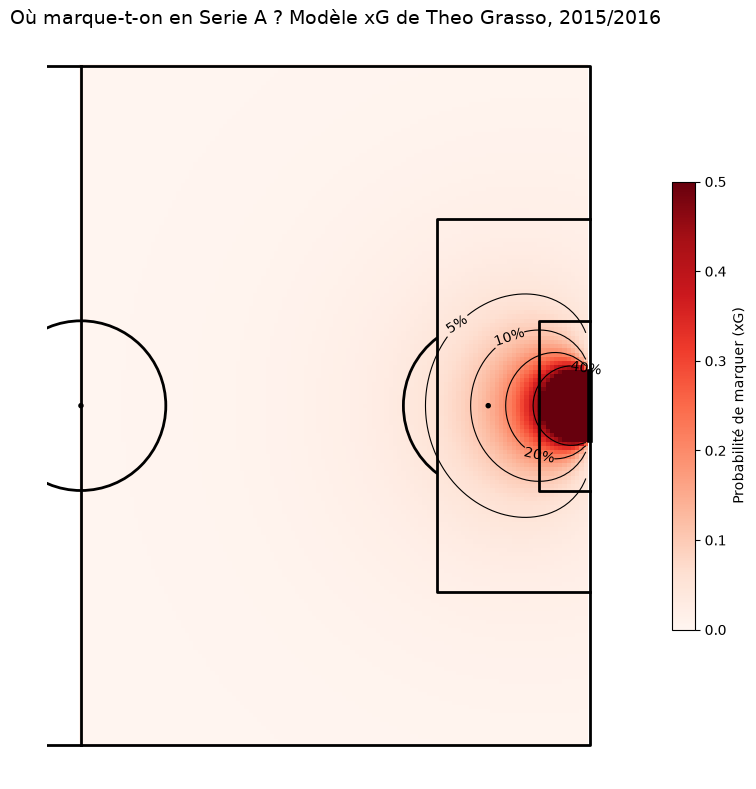

In [14]:
# Grille de points tous les 0,5 sur la moitié de terrain adverse
gx, gy = np.meshgrid(np.arange(60, 120, 0.5), np.arange(0, 80.5, 0.5))

# Un point par ligne dans un tableau
grille = pd.DataFrame({"x": gx.ravel(), "y": gy.ravel()})

# Distance et angle de chaque point, comme pour les vrais tirs
ex, ey = 120 - grille["x"], 40 - grille["y"]
grille["distance"] = np.sqrt(ex**2 + ey**2)
grille["angle"] = np.degrees(np.arctan2(8 * ex, ex**2 + ey**2 - 16))

# Tir standard : du pied, aucune situation particulière
for info in ["tete", "face_a_face", "premiere_intention", "sous_pression",
             "contre_attaque", "apres_corner", "apres_coup_franc", "apres_touche", "gardien_hors_cadre"]:
    grille[info] = 0

# Défenseurs devant et position du gardien : valeurs les plus courantes de la saison
grille["defenseurs_devant"] = tirs["defenseurs_devant"].median()
grille["gardien_distance_but"] = tirs["gardien_distance_but"].median()

# xG de chaque point, remis en forme de grille
xg_grille = modele_final.predict_proba(grille[infos_v3])[:, 1].reshape(gx.shape)

# Moitié de terrain, avec les lignes dessinées par-dessus les couleurs
pitch = Pitch(pitch_type="statsbomb", half=True, line_color="black", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 8))

# Couleur de chaque carré selon son xG
carte = ax.pcolormesh(gx, gy, xg_grille, cmap="Reds", shading="auto", vmin=0, vmax=0.5)

# Lignes de niveau à 5 %, 10 %, 20 % et 40 %, avec leur pourcentage écrit dessus
niveaux = ax.contour(gx, gy, xg_grille, levels=[0.05, 0.1, 0.2, 0.4], colors="black", linewidths=0.8)
ax.clabel(niveaux, fmt=lambda v: f"{v:.0%}", fontsize=10)

# Légende des couleurs et titre
fig.colorbar(carte, ax=ax, shrink=0.6, label="Probabilité de marquer (xG)")
ax.set_title("Où marque-t-on en Serie A ? Modèle xG de Theo Grasso, 2015/2016", fontsize=14)

# Enregistrement de l'image
plt.savefig("carte_xg_serie_a.png", dpi=200, bbox_inches="tight")
plt.show()

### Les 5 plus grosses occasions et les 5 tirs les plus difficiles d'un joueur

Chaque tir est numéroté, son xG est écrit sous le terrain. Le terrain de gauche est zoomé près du but pour écarter les points. Il suffit de changer le nom du joueur pour refaire le visuel.

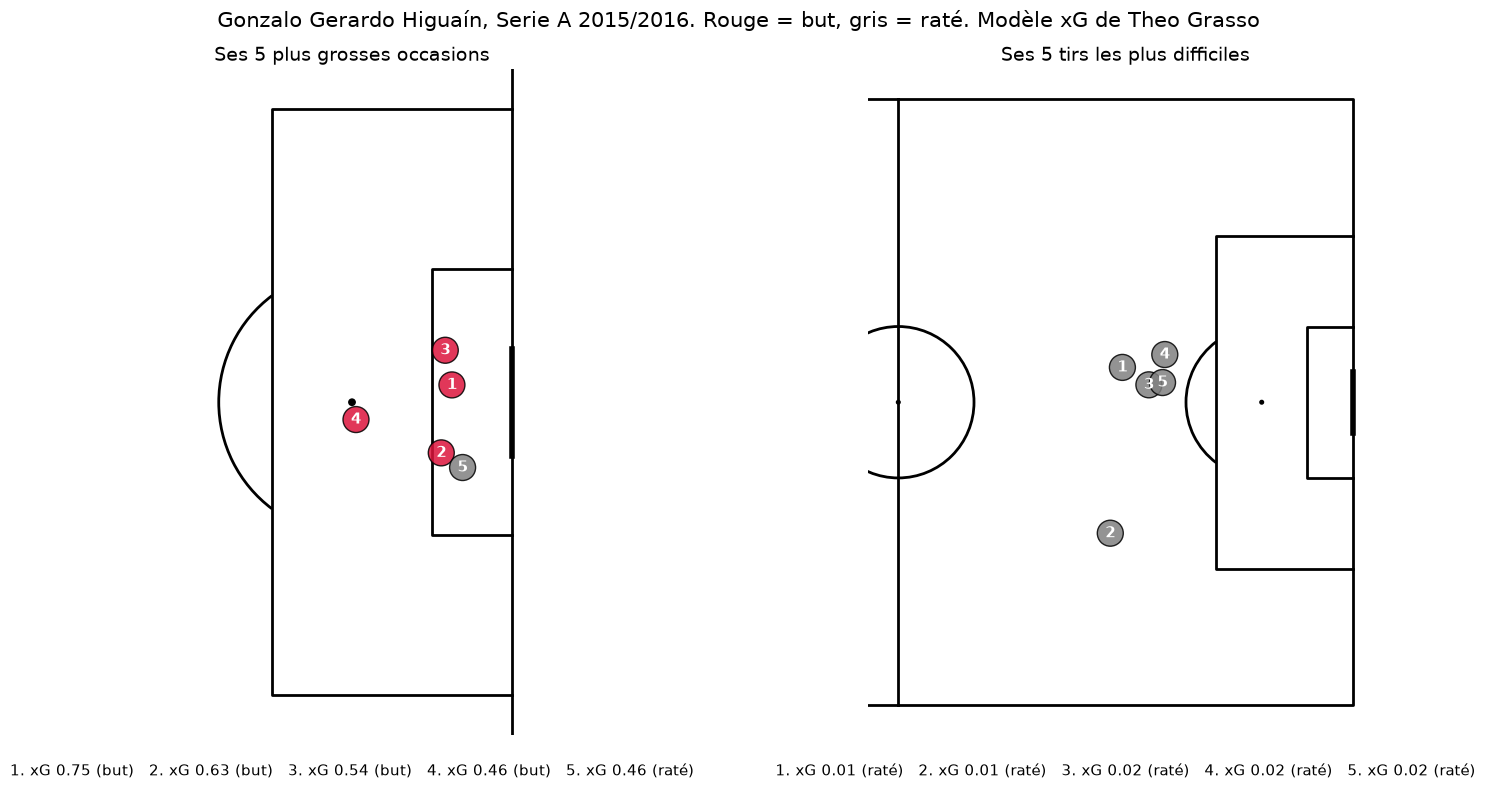

In [15]:
# Le joueur choisi
joueur = "Gonzalo Gerardo Higuaín"

# Ses tirs
tirs_joueur = tirs[tirs["player"] == joueur]

# Ses 5 tirs avec le xG le plus haut, et les 5 avec le xG le plus bas
top5 = tirs_joueur.nlargest(5, "xg_theo")
flop5 = tirs_joueur.nsmallest(5, "xg_theo")

# Deux moitiés de terrain côte à côte
pitch = Pitch(pitch_type="statsbomb", half=True, line_color="black")
fig, axs = pitch.draw(ncols=2, figsize=(16, 8))

# Les deux terrains : (terrain, tirs, titre, zoom ou non)
terrains = [(axs[0], top5, "Ses 5 plus grosses occasions", True),
            (axs[1], flop5, "Ses 5 tirs les plus difficiles", False)]

# Dessin de chaque terrain
for ax, groupe, titre, zoom in terrains:
    # Tirs numérotés de 1 à 5
    groupe = groupe.reset_index(drop=True)
    # Rouge si but, gris si raté
    couleurs = ["crimson" if b == 1 else "grey" for b in groupe["but"]]
    # Points de taille moyenne, un peu transparents
    pitch.scatter(groupe["x"], groupe["y"], s=350, c=couleurs, alpha=0.85, edgecolors="black", zorder=3, ax=ax)
    # Numéro au centre de chaque point
    for i, t in groupe.iterrows():
        pitch.annotate(str(i + 1), xy=(t["x"], t["y"]), ax=ax, ha="center", va="center",
                       color="white", fontsize=11, fontweight="bold", zorder=4)
    # Zoom sur les 25 derniers mètres pour les grosses occasions
    if zoom:
        ax.set_xlim(95, 121)
        ax.set_ylim(65, 15)
    # Liste sous le terrain : numéro, xG et résultat
    legende = "   ".join(f"{i + 1}. xG {t['xg_theo']:.2f} ({'but' if t['but'] == 1 else 'raté'})"
                         for i, t in groupe.iterrows())
    ax.text(0.5, -0.06, legende, transform=ax.transAxes, ha="center", fontsize=11)
    # Titre du terrain
    ax.set_title(titre, fontsize=14)

# Titre général et enregistrement
fig.suptitle(f"{joueur}, Serie A 2015/2016. Rouge = but, gris = raté. Modèle xG de Theo Grasso", fontsize=15)
plt.savefig("top_flop_xg.png", dpi=200, bbox_inches="tight")
plt.show()

### L'occasion la plus facile ratée et le but le plus difficile marqué

Pour chaque tir, on dessine aussi les joueurs visibles au moment de la frappe et la zone de tir vers les poteaux. On voit ainsi pourquoi le modèle donne ce xG. La photo StatsBomb ne montre que les joueurs visibles à la caméra, il peut donc manquer des joueurs loin de l'action.

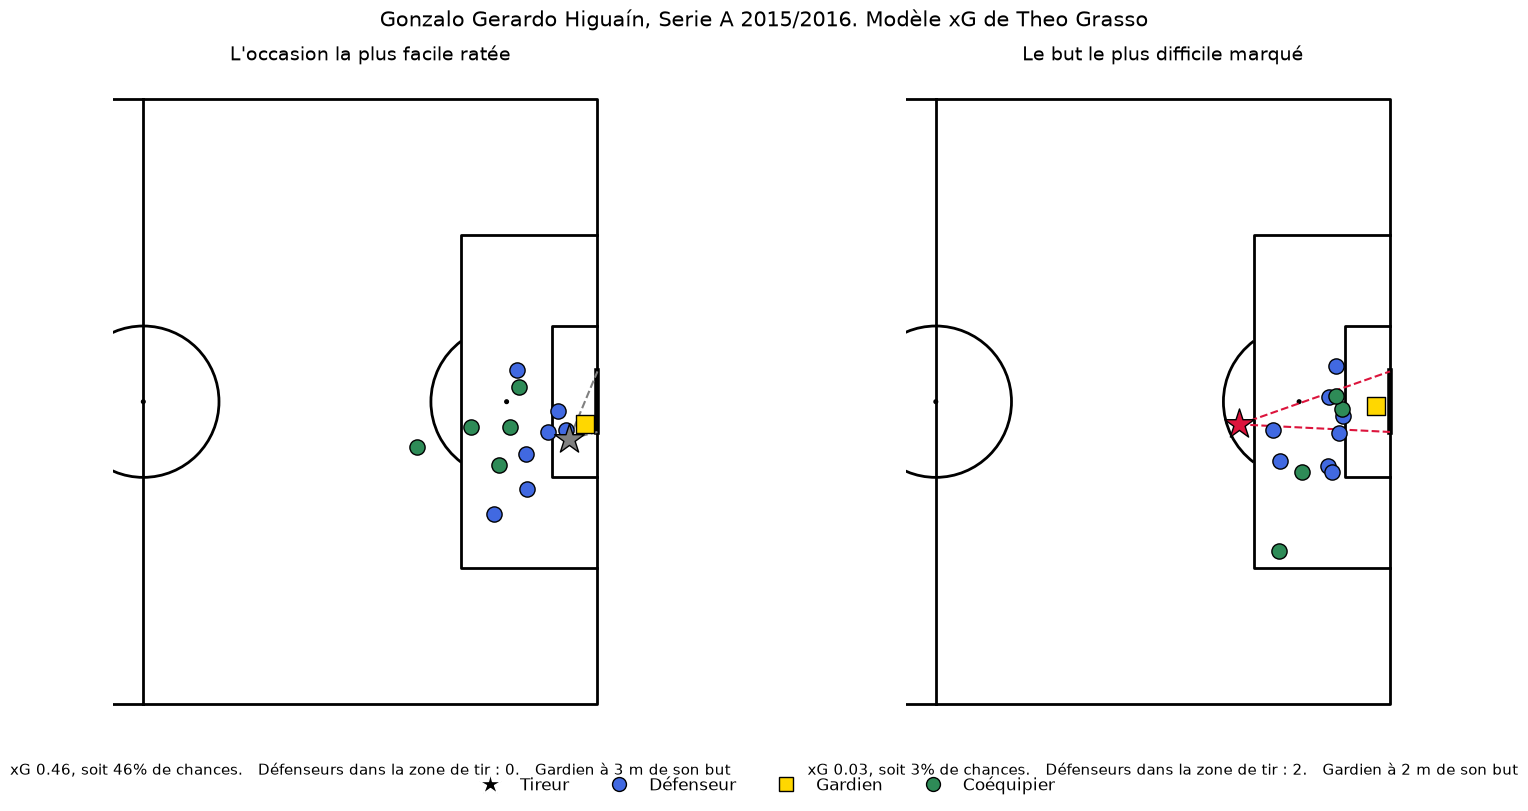

In [16]:
# Le joueur choisi
joueur = "Gonzalo Gerardo Higuaín"

# Ses tirs
tirs_joueur = tirs[tirs["player"] == joueur]

# Son occasion ratée la plus facile et son but le plus difficile
rate_facile = tirs_joueur[tirs_joueur["but"] == 0].nlargest(1, "xg_theo")
but_difficile = tirs_joueur[tirs_joueur["but"] == 1].nsmallest(1, "xg_theo")

# Deux moitiés de terrain côte à côte
pitch = Pitch(pitch_type="statsbomb", half=True, line_color="black")
fig, axs = pitch.draw(ncols=2, figsize=(16, 8))

# Les deux terrains : (terrain, tir, titre, couleur du tireur)
terrains = [(axs[0], rate_facile, "L'occasion la plus facile ratée", "grey"),
            (axs[1], but_difficile, "Le but le plus difficile marqué", "crimson")]

# Dessin de chaque terrain
for ax, groupe, titre, couleur in terrains:
    # Le tir et son numéro de ligne d'origine
    numero = groupe.index[0]
    t = groupe.iloc[0]
    # La photo des joueurs de ce tir, dans le fichier complet
    photo = brut.loc[numero, "shot_freeze_frame"]
    # Zone de tir : du tireur vers chaque poteau, en pointillés
    for poteau_y in (36, 44):
        pitch.lines(t["x"], t["y"], 120, poteau_y, ax=ax, color=couleur, lw=1.5, linestyle="--", zorder=2)
    # Chaque joueur visible sur la photo
    if isinstance(photo, list):
        for j in photo:
            # Position du joueur
            jx, jy = j["location"]
            # Coéquipier : point vert
            if j["teammate"]:
                pitch.scatter(jx, jy, s=120, c="seagreen", edgecolors="black", zorder=3, ax=ax)
            # Gardien adverse : carré jaune
            elif j["position"]["name"] == "Goalkeeper":
                pitch.scatter(jx, jy, s=180, c="gold", marker="s", edgecolors="black", zorder=3, ax=ax)
            # Défenseur adverse : point bleu
            else:
                pitch.scatter(jx, jy, s=120, c="royalblue", edgecolors="black", zorder=3, ax=ax)
    # Le tireur, en étoile
    pitch.scatter(t["x"], t["y"], s=500, c=couleur, marker="*", edgecolors="black", zorder=4, ax=ax)
    # Sous le terrain : xG, défenseurs dans la zone de tir et distance du gardien
    infos_tir = (f"xG {t['xg_theo']:.2f}, soit {t['xg_theo']:.0%} de chances.   "
                 f"Défenseurs dans la zone de tir : {int(t['defenseurs_devant'])}.   "
                 f"Gardien à {t['gardien_distance_but']:.0f} m de son but")
    ax.text(0.5, -0.06, infos_tir, transform=ax.transAxes, ha="center", fontsize=11)
    # Titre du terrain
    ax.set_title(titre, fontsize=14)

# Légende commune des symboles
legende = [Line2D([0], [0], marker="*", color="w", markerfacecolor="black", markersize=16, label="Tireur"),
           Line2D([0], [0], marker="o", color="w", markerfacecolor="royalblue", markeredgecolor="black", markersize=10, label="Défenseur"),
           Line2D([0], [0], marker="s", color="w", markerfacecolor="gold", markeredgecolor="black", markersize=10, label="Gardien"),
           Line2D([0], [0], marker="o", color="w", markerfacecolor="seagreen", markeredgecolor="black", markersize=10, label="Coéquipier")]
fig.legend(handles=legende, loc="lower center", ncol=4, fontsize=12, frameon=False, bbox_to_anchor=(0.5, -0.02))

# Titre général et enregistrement
fig.suptitle(f"{joueur}, Serie A 2015/2016. Modèle xG de Theo Grasso", fontsize=15)
plt.savefig("rate_facile_but_difficile.png", dpi=200, bbox_inches="tight")
plt.show()

## Étape 7. Application au Milan, saison 2025/2026

Les données gratuites StatsBomb s'arrêtent en 2015/2016. Pour le Milan récent, on utilise Understat, qui donne la position de chaque tir et son propre xG, mais pas la photo des joueurs. Le modèle appliqué au Milan devra donc se limiter aux infos qu'Understat connaît : distance, angle, tête, après corner, après coup franc.

On commence par récupérer tous les tirs de la saison et par regarder comment Understat nomme les équipes, les situations et les parties du corps.

In [17]:
# On importe soccerdata sous le petit nom "sd"
import soccerdata as sd

# Lecture d'Understat pour la Serie A 2025/2026 (changer en "2026/2027" pour la saison en cours)
understat = sd.Understat(leagues="ITA-Serie A", seasons="2025/2026")

# Tous les tirs de la saison, avec équipe et joueur en colonnes normales
tirs_us = understat.read_shot_events().reset_index()

# Nom exact des équipes, pour vérifier comment Understat écrit le Milan
print(sorted(tirs_us["team"].unique()))

# Nombre total de tirs de la saison
print("Tirs en Serie A 2025/2026 :", len(tirs_us))

# Valeurs possibles pour la situation, la partie du corps et le résultat
print(tirs_us["situation"].value_counts())
print(tirs_us["body_part"].value_counts())
print(tirs_us["result"].value_counts())

[2026-10-18 20:37:28] INFO     TLSLibrary:_load_library:397 - Successfully loaded TLS library: D:\Anaconda\Lib\site-packages\tls_requests\bin\tls-client-xgo-1.13.1-windows-amd64.dll


[10/18/26 20:37:28] INFO     Successfully loaded TLS library:                                      ]8;id=1056147;file://D:\Anaconda\Lib\site-packages\tls_requests\models\libraries.py\libraries.py]8;;\:]8;id=1056148;file://D:\Anaconda\Lib\site-packages\tls_requests\models\libraries.py#397\397]8;;\
                             D:\Anaconda\Lib\site-packages\tls_requests\bin\tls-client-xgo-1.13.1-                 
                             windows-amd64.dll                                                                     

['AC Milan', 'Atalanta', 'Bologna', 'Cagliari', 'Como', 'Cremonese', 'Fiorentina', 'Genoa', 'Inter', 'Juventus', 'Lazio', 'Lecce', 'Napoli', 'Parma Calcio 1913', 'Pisa', 'Roma', 'Sassuolo', 'Torino', 'Udinese', 'Verona']
Tirs en Serie A 2025/2026 : 9373
situation
Open Play          6868
From Corner        1466
Set Piece           653
Direct Freekick     280
Name: count, dtype: int64[pyarrow]
body_part
Right Foot    4280
Left Foot     3290
Name: count, dtype: int64[pyarrow]
result
Missed Shot     3559
Blocked Shot    2622
Saved Shot      2094
Goal             900
Shot On Post     176
Own Goal          22
Name: count, dtype: int64[pyarrow]


### Vérification des données Understat

Trois pièges apparaissent. La partie du corps n'est remplie que pour les tirs du pied : environ 1 800 tirs ont une case vide, ce qui ressemble aux têtes. 106 tirs n'ont pas de situation, ce qui ressemble aux penaltys. Et 22 buts contre son camp ne sont pas de vrais tirs. On vérifie les deux premiers avant de s'en servir.

In [18]:
# Colonne qui dit si la partie du corps est vide (True) ou remplie (False)
tirs_us["corps_vide"] = tirs_us["body_part"].isna()

# Pour chaque groupe : nombre de tirs, position moyenne (1 = ligne de but adverse) et part de tirs après corner
tirs_us.groupby("corps_vide").agg(
    nb_tirs=("result", "count"),
    position_moyenne=("location_x", lambda v: v.astype(float).mean()),
    part_apres_corner=("situation", lambda s: (s == "From Corner").mean()),
).round(3)

,nb_tirs,position_moyenne,part_apres_corner
corps_vide,,,
False,7570,0.835,0.094
True,1803,0.916,0.422


In [19]:
# Les tirs sans situation : si ce sont des penaltys, le xG moyen sera autour de 0,76 et la plupart seront des buts
sans_situation = tirs_us[tirs_us["situation"].isna()]

# Nombre de tirs, xG Understat moyen et résultats
print("Tirs sans situation :", len(sans_situation))
print("xG Understat moyen :", round(sans_situation["xg"].astype(float).mean(), 3))
print(sans_situation["result"].value_counts())

Tirs sans situation : 106
xG Understat moyen : 0.761
result
Goal            81
Saved Shot      22
Missed Shot      2
Shot On Post     1
Name: count, dtype: int64[pyarrow]


**Lecture.** Les tirs à la case vide sont plus proches du but (0,916 contre 0,835) et viennent d'un corner dans 42 % des cas, contre 9 % pour les autres : ce sont bien des têtes. Les 106 tirs sans situation ont un xG moyen de 0,761 et 81 buts : ce sont des penaltys.

### Préparation des tirs Understat et modèle compatible

Understat donne la position entre 0 et 1, on la convertit à l'échelle StatsBomb. On écarte les penaltys, les coups francs directs et les buts contre son camp, comme pour StatsBomb.

Le modèle appliqué ici n'utilise que les infos communes aux deux sources : distance, angle, tête, après corner, après coup franc. Il est entraîné sur tous les tirs StatsBomb 2015/2016.

In [20]:
# On retire les buts contre son camp, les coups francs directs et les tirs sans situation (les penaltys)
us = tirs_us[(tirs_us["result"] != "Own Goal")
             & (tirs_us["situation"] != "Direct Freekick")
             & (tirs_us["situation"].notna())].copy()

# Conversion de la position à l'échelle StatsBomb (120 de long, 80 de large)
us["x"] = us["location_x"].astype(float) * 120
us["y"] = us["location_y"].astype(float) * 80

# Distance et angle, exactement comme pour StatsBomb
ex, ey = 120 - us["x"], 40 - us["y"]
us["distance"] = np.sqrt(ex**2 + ey**2)
us["angle"] = np.degrees(np.arctan2(8 * ex, ex**2 + ey**2 - 16))

# Tête : la case "partie du corps" est vide (vérifié plus haut)
us["tete"] = us["body_part"].isna().astype(int)

# Situation : après corner, ou après coup franc indirect ("Set Piece" chez Understat)
us["apres_corner"] = (us["situation"] == "From Corner").astype(int)
us["apres_coup_franc"] = (us["situation"] == "Set Piece").astype(int)

# 1 si but, 0 sinon
us["but"] = (us["result"] == "Goal").astype(int)

# Le xG calculé par Understat, pour comparer
us["xg_understat"] = us["xg"].astype(float)

# Nombre de tirs gardés
print("Tirs gardés :", len(us))

Tirs gardés : 8965


In [21]:
# Les seules infos que StatsBomb et Understat ont en commun
infos_us = ["distance", "angle", "tete", "apres_corner", "apres_coup_franc"]

# Note du modèle compatible sur les tirs StatsBomb de test
modele_test = LogisticRegression(max_iter=1000).fit(app[infos_us], app["but"])
print("AUC du modèle compatible sur StatsBomb :",
      round(roc_auc_score(test["but"], modele_test.predict_proba(test[infos_us])[:, 1]), 3))

# Modèle final compatible, entraîné sur tous les tirs StatsBomb 2015/2016
modele_us = LogisticRegression(max_iter=1000).fit(tirs[infos_us], tirs["but"])

# Ton xG pour chaque tir de la Serie A 2025/2026
us["xg_theo"] = modele_us.predict_proba(us[infos_us])[:, 1]

# Comparaison sur toute la saison
print("Vrais buts :", us["but"].sum())
print("Total xG Theo :", round(us["xg_theo"].sum(), 1))
print("Total xG Understat :", round(us["xg_understat"].sum(), 1))
print("AUC Theo :", round(roc_auc_score(us["but"], us["xg_theo"]), 3))
print("AUC Understat :", round(roc_auc_score(us["but"], us["xg_understat"]), 3))

AUC du modèle compatible sur StatsBomb : 0.802
Vrais buts : 807
Total xG Theo : 763.4
Total xG Understat : 980.4
AUC Theo : 0.748
AUC Understat : 0.796


In [22]:
# Pour chaque situation : tirs, vrais buts, xG Theo et xG Understat, pour voir où apparaissent les écarts
us.groupby("situation").agg(
    tirs=("but", "count"),
    buts=("but", "sum"),
    xg_theo=("xg_theo", "sum"),
    xg_understat=("xg_understat", "sum"),
).round(1)

,tirs,buts,xg_theo,xg_understat
situation,,,,
From Corner,1463,127,120.2,149.1
Open Play,6849,626,577.1,761.8
Set Piece,653,54,66.1,69.5


**Lecture.** Le modèle compatible obtient 0,802 d'AUC sur StatsBomb et 0,748 sur Understat. La baisse s'explique par des positions de tir moins précises chez Understat et par le peu d'infos disponibles. Au total, il prévoit 763 xG pour 807 buts, soit environ 5 % de moins que la réalité.

Understat prévoit 980 xG pour 807 buts, un écart de 21 % présent dans toutes les situations. Deux explications possibles : une saison de Serie A particulièrement maladroite, ou un modèle Understat plus généreux. Pour trancher, on refait le calcul sur la saison 2024/2025.

In [23]:
# On lit les tirs de Serie A 2024/2025 sur Understat (si le site ne répond pas, attendre et relancer plus tard)
tirs_24 = sd.Understat(leagues="ITA-Serie A", seasons="2024/2025").read_shot_events().reset_index()

# On garde les mêmes tirs que pour 2025/2026 : sans buts contre son camp, coups francs directs ni penaltys
tirs_24 = tirs_24[(tirs_24["result"] != "Own Goal")
                  & (tirs_24["situation"] != "Direct Freekick")
                  & (tirs_24["situation"].notna())]

# Nombre de vrais buts et total de xG Understat
buts_24 = (tirs_24["result"] == "Goal").sum()
xg_24 = tirs_24["xg"].astype(float).sum()

# Écart en pourcentage, à comparer aux 21 % de 2025/2026
print("Buts :", buts_24, "| xG Understat :", round(xg_24, 1),
      "| Écart :", round((xg_24 - buts_24) / buts_24 * 100, 1), "%")

Buts : 842 | xG Understat : 956.4 | Écart : 13.6 %


**Lecture.** En 2024/2025, Understat prévoit 956,4 xG pour 842 buts, soit 13,6 % de trop. Sur deux saisons d'affilée, le xG Understat dépasse les buts réels de 14 à 21 % sur les tirs hors penaltys. Une partie de l'écart vient donc du modèle Understat, plus généreux, et l'autre de la saison 2025/2026, plus maladroite que d'habitude. Avec deux saisons seulement, la conclusion reste prudente.

### Le Milan 2025/2026

Classement des joueurs du Milan avec au moins 10 tirs. Avec si peu de tirs, la chance pèse beaucoup : seuls les gros écarts sont significatifs.

In [24]:
# Les tirs du Milan
milan = us[us["team"] == "AC Milan"]

# Bilan de l'équipe
print("Milan, Serie A 2025/2026 (hors penaltys et coups francs directs)")
print("Tirs :", len(milan), "| Buts :", milan["but"].sum(),
      "| xG Theo :", round(milan["xg_theo"].sum(), 1),
      "| xG Understat :", round(milan["xg_understat"].sum(), 1))

# Pour chaque joueur : tirs, buts, xG Theo et xG Understat
joueurs_milan = milan.groupby("player").agg(
    tirs=("but", "count"),
    buts=("but", "sum"),
    xg_theo=("xg_theo", "sum"),
    xg_understat=("xg_understat", "sum"),
)

# Joueurs avec au moins 10 tirs
joueurs_milan = joueurs_milan[joueurs_milan["tirs"] >= 10]

# Buts moins xG Theo
joueurs_milan["buts_moins_xg"] = joueurs_milan["buts"] - joueurs_milan["xg_theo"]

# Classement du meilleur au moins bon finisseur
joueurs_milan.sort_values("buts_moins_xg", ascending=False).round(1)

Milan, Serie A 2025/2026 (hors penaltys et coups francs directs)
Tirs : 484 | Buts : 46 | xG Theo : 45.2 | xG Understat : 58.3


,tirs,buts,xg_theo,xg_understat,buts_moins_xg
player,,,,,
Adrien Rabiot,46,6,3.1,4.4,2.9
Christian Pulisic,52,8,5.5,8.7,2.5
Zachary Athekame,13,2,0.4,0.4,1.6
Strahinja Pavlovic,25,5,3.5,3.8,1.5
Davide Bartesaghi,17,2,0.8,1.1,1.2
Luka Modric,19,2,1.0,1.2,1.0
Alexis Saelemaekers,43,3,2.6,3.6,0.4
Rafael Leão,61,7,7.0,8.1,-0.0
Ruben Loftus-Cheek,29,3,3.2,4.1,-0.2


**Lecture.** Le Milan marque 46 buts pour 45,2 xG Theo : l'équipe a marqué exactement ce que ses occasions valaient.

Rabiot marque 6 buts pour 3,1 xG, les deux modèles s'accordent sur sa surperformance. Giménez ne marque aucun but pour 3,0 xG, Nkunku 2 buts pour 4,4. Leão est pile dans la norme avec 7 buts pour 7,0 xG.

Pulisic est le cas qui divise : 8 buts pour 5,5 xG selon ce modèle, mais 8,7 selon Understat. Understat connaît des infos que ce modèle n'a pas, comme le type de passe décisive, et voit donc ses occasions différemment.

### Les attaquants du Milan

On compare les cinq attaquants entre eux, car comparer un milieu et un attaquant n'aurait pas de sens : ils n'ont pas le même rôle ni les mêmes occasions. Pour chacun, sa plus grosse occasion ratée et son but le plus difficile. Understat ne fournit pas la position des autres joueurs, seul le tireur est dessiné.

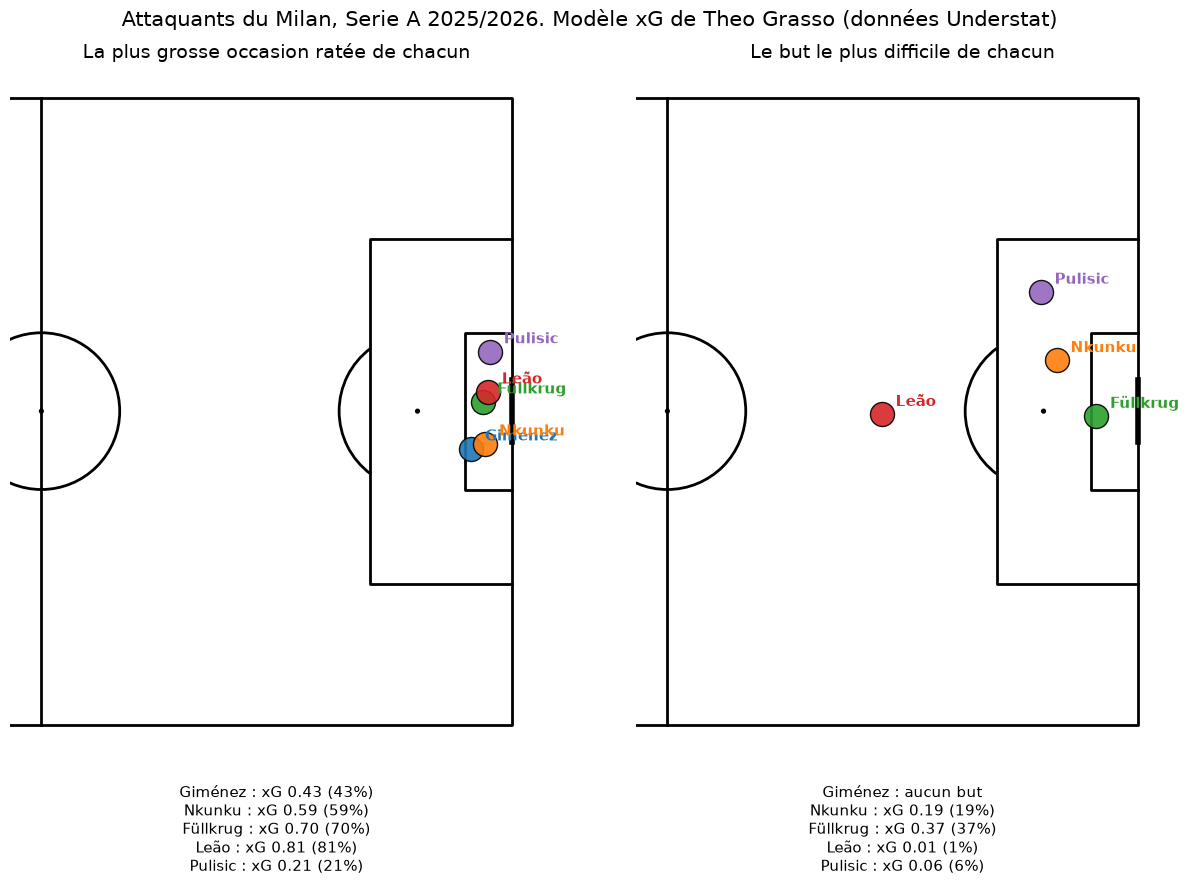

In [25]:
# Les cinq attaquants comparés, avec une couleur fixe pour chacun
attaquants = {
    "Santiago Giménez": "tab:blue",
    "Christopher Nkunku": "tab:orange",
    "Niclas Füllkrug": "tab:green",
    "Rafael Leão": "tab:red",
    "Christian Pulisic": "tab:purple",
}

# Deux moitiés de terrain côte à côte
pitch = Pitch(pitch_type="statsbomb", half=True, line_color="black")
fig, axs = pitch.draw(ncols=2, figsize=(16, 9))

# Textes à écrire sous chaque terrain, un par joueur
lignes_gauche, lignes_droite = [], []

# On traite chaque attaquant un par un
for nom, couleur in attaquants.items():
    # Ses tirs de la saison
    t_joueur = milan[milan["player"] == nom]
    # Son nom de famille seul, pour des étiquettes courtes
    court = nom.split()[-1]

    # Terrain de gauche : son occasion ratée avec le xG le plus haut
    rates = t_joueur[t_joueur["but"] == 0]
    if len(rates) > 0:
        # Le tir raté le plus facile
        r = rates.loc[rates["xg_theo"].idxmax()]
        # Le point du tir, à la couleur du joueur
        pitch.scatter(r["x"], r["y"], s=300, c=couleur, edgecolors="black", alpha=0.9, zorder=3, ax=axs[0])
        # Son nom à côté du point
        pitch.annotate(court, xy=(r["x"], r["y"]), ax=axs[0], xytext=(10, 6), textcoords="offset points",
                       fontsize=11, color=couleur, fontweight="bold", zorder=4)
        # La ligne de texte sous le terrain
        lignes_gauche.append(f"{court} : xG {r['xg_theo']:.2f} ({r['xg_theo']:.0%})")

    # Terrain de droite : son but avec le xG le plus bas
    buts = t_joueur[t_joueur["but"] == 1]
    if len(buts) > 0:
        # Le but le plus difficile
        b = buts.loc[buts["xg_theo"].idxmin()]
        # Le point du but, à la couleur du joueur
        pitch.scatter(b["x"], b["y"], s=300, c=couleur, edgecolors="black", alpha=0.9, zorder=3, ax=axs[1])
        # Son nom à côté du point
        pitch.annotate(court, xy=(b["x"], b["y"]), ax=axs[1], xytext=(10, 6), textcoords="offset points",
                       fontsize=11, color=couleur, fontweight="bold", zorder=4)
        # La ligne de texte sous le terrain
        lignes_droite.append(f"{court} : xG {b['xg_theo']:.2f} ({b['xg_theo']:.0%})")
    else:
        # Aucun but : on l'écrit sous le terrain
        lignes_droite.append(f"{court} : aucun but")

# Textes sous chaque terrain, sur plusieurs lignes
axs[0].text(0.5, -0.04, "\n".join(lignes_gauche), transform=axs[0].transAxes, ha="center", va="top", fontsize=11)
axs[1].text(0.5, -0.04, "\n".join(lignes_droite), transform=axs[1].transAxes, ha="center", va="top", fontsize=11)

# Titres des deux terrains
axs[0].set_title("La plus grosse occasion ratée de chacun", fontsize=14)
axs[1].set_title("Le but le plus difficile de chacun", fontsize=14)

# Titre général et enregistrement
fig.suptitle("Attaquants du Milan, Serie A 2025/2026. Modèle xG de Theo Grasso (données Understat)", fontsize=15)
plt.savefig("milan_attaquants_xg.png", dpi=200, bbox_inches="tight")
plt.show()

## Étape 8. Récupération des cinq grands championnats 2015/2016

StatsBomb offre gratuitement la saison 2015/2016 de la Serie A, de la Premier League, de la Liga et de la Ligue 1 en entier. Pour la Bundesliga, seuls 34 matchs sont disponibles. On récupère les tirs et, pour chaque tir, sa passe décisive.

Un fichier est enregistré par championnat : si le téléchargement coupe, les championnats terminés ne sont pas retéléchargés. Chaque match a droit à trois essais. Compter 40 minutes à 1 heure.

In [26]:
# On importe l'outil qui permet de faire une pause entre deux essais
import time

# Les cinq championnats, avec un nom court pour les fichiers
championnats = {
    "Serie A": "serie_a",
    "Premier League": "premier_league",
    "La Liga": "liga",
    "1. Bundesliga": "bundesliga",
    "Ligue 1": "ligue_1",
}

# Les infos de la passe décisive qui nous intéressent (on garde seulement celles qui existent)
colonnes_passe = ["id", "pass_cross", "pass_through_ball", "pass_cut_back", "pass_height", "pass_technique", "pass_switch"]

# Liste des matchs qui n'ont pas pu être récupérés
matchs_rates = []

# On traite chaque championnat un par un
for nom, court in championnats.items():
    # Noms des fichiers de ce championnat
    fichier_tirs = f"tirs_{court}_2015_16.pkl"
    fichier_passes = f"passes_{court}_2015_16.pkl"
    # Si les deux fichiers existent déjà, ce championnat est fait
    if os.path.exists(fichier_tirs) and os.path.exists(fichier_passes):
        print(nom, ": déjà téléchargé")
        continue
    # La saison 2015/2016 de ce championnat
    ligne = competitions[(competitions["competition_name"] == nom) & (competitions["season_name"] == "2015/2016")]
    # Liste des matchs
    matchs_champ = sb.matches(competition_id=ligne["competition_id"].iloc[0], season_id=ligne["season_id"].iloc[0])
    # Listes vides pour les tirs et les passes décisives
    liste_tirs, liste_passes = [], []
    # On passe sur chaque match
    for i, match_id in enumerate(matchs_champ["match_id"]):
        # Jusqu'à trois essais par match
        for essai in range(3):
            try:
                # Toutes les actions du match
                actions = sb.events(match_id=match_id)
                # Si ça a marché, on sort de la boucle des essais
                break
            except Exception:
                # Sinon, on attend 5 secondes avant de réessayer
                time.sleep(5)
        else:
            # Après trois échecs, on note le match et on passe au suivant
            matchs_rates.append((nom, match_id))
            continue
        # Les tirs du match, avec le match et le championnat
        tirs_match = actions[actions["type"] == "Shot"].copy()
        tirs_match["match_id"] = match_id
        tirs_match["championnat"] = nom
        # Les passes décisives : les passes dont l'identifiant est cité par un tir
        if "shot_key_pass_id" in tirs_match.columns:
            ids = tirs_match["shot_key_pass_id"].dropna()
            passes_match = actions[actions["id"].isin(ids)]
            # On garde seulement les colonnes de passe qui existent dans ce match
            passes_match = passes_match[[c for c in colonnes_passe if c in passes_match.columns]]
            liste_passes.append(passes_match)
        # On range les tirs de ce match
        liste_tirs.append(tirs_match)
        # Tous les 50 matchs, on affiche l'avancement
        if (i + 1) % 50 == 0:
            print(nom, ":", i + 1, "matchs sur", len(matchs_champ))
    # On colle et on enregistre les tirs et les passes du championnat
    pd.concat(liste_tirs, ignore_index=True).to_pickle(fichier_tirs)
    pd.concat(liste_passes, ignore_index=True).to_pickle(fichier_passes)
    print(nom, ": terminé et enregistré")

# Bilan des matchs ratés
print("Matchs non récupérés :", matchs_rates)

Serie A : déjà téléchargé
Premier League : déjà téléchargé
La Liga : déjà téléchargé
1. Bundesliga : déjà téléchargé
Ligue 1 : déjà téléchargé
Matchs non récupérés : []


In [27]:
# Contrôle : pour chaque championnat, nombre de matchs, de tirs et de passes décisives
for court in championnats.values():
    t = pd.read_pickle(f"tirs_{court}_2015_16.pkl")
    p = pd.read_pickle(f"passes_{court}_2015_16.pkl")
    print(court, ": matchs", t["match_id"].nunique(), "| tirs", len(t), "| passes décisives", len(p))

serie_a : matchs 380 | tirs 9998 | passes décisives 7136
premier_league : matchs 380 | tirs 9908 | passes décisives 7175
liga : matchs 380 | tirs 9168 | passes décisives 6485
bundesliga : matchs 34 | tirs 840 | passes décisives 570
ligue_1 : matchs 377 | tirs 8814 | passes décisives 6239


## Étape 9. Modèle sur les cinq championnats, avec la passe décisive

Pour chaque tir, on ajoute la passe qui l'a précédé : centre, passe en profondeur, passe en retrait depuis la ligne de but (cut back), passe aérienne, ou aucune passe (dribble, ballon renvoyé).

On compare ensuite, sur les mêmes tirs jamais vus : la v3 apprise sur la Serie A seule, la v3 apprise sur les cinq championnats, la v4 avec la passe décisive, un gradient boosting et StatsBomb.

In [28]:
# Fonction qui prépare les tirs d'un championnat, comme à l'étape 2, plus la passe décisive
def preparer(brut, passes):
    # On garde uniquement les tirs dans le jeu
    t = brut[brut["shot_type"] == "Open Play"].copy()
    # Position du tir
    t["x"] = t["location"].apply(lambda pos: pos[0])
    t["y"] = t["location"].apply(lambda pos: pos[1])
    # Distance et angle vers le but
    ex, ey = 120 - t["x"], 40 - t["y"]
    t["distance"] = np.sqrt(ex**2 + ey**2)
    t["angle"] = np.degrees(np.arctan2(8 * ex, ex**2 + ey**2 - 16))
    # Type de tir
    t["tete"] = (t["shot_body_part"] == "Head").astype(int)
    t["face_a_face"] = oui_non(t, "shot_one_on_one")
    t["premiere_intention"] = oui_non(t, "shot_first_time")
    t["sous_pression"] = oui_non(t, "under_pressure")
    # Situation de jeu
    t["contre_attaque"] = (t["play_pattern"] == "From Counter").astype(int)
    t["apres_corner"] = (t["play_pattern"] == "From Corner").astype(int)
    t["apres_coup_franc"] = (t["play_pattern"] == "From Free Kick").astype(int)
    t["apres_touche"] = (t["play_pattern"] == "From Throw In").astype(int)
    # Photo des joueurs : défenseurs devant et gardien
    t = t.join(t.apply(lire_photo, axis=1))
    # Passes décisives rangées par identifiant, sans doublon
    p = passes.drop_duplicates("id").set_index("id")
    # Pour chaque tir, l'identifiant de sa passe décisive (vide s'il n'y en a pas)
    cle = t["shot_key_pass_id"] if "shot_key_pass_id" in t.columns else pd.Series(np.nan, index=t.index)
    # Petite fonction : va chercher une info de la passe décisive de chaque tir
    def passe(col):
        return cle.map(p[col]) if col in p.columns else pd.Series(np.nan, index=t.index)
    # 1 si le tir n'a pas de passe décisive
    t["sans_passe"] = cle.isna().astype(int)
    # 1 si la passe décisive est un centre
    t["centre"] = (passe("pass_cross") == True).astype(int)
    # 1 si c'est une passe en profondeur (StatsBomb la note de deux façons selon les saisons)
    t["passe_profondeur"] = ((passe("pass_through_ball") == True) | (passe("pass_technique") == "Through Ball")).astype(int)
    # 1 si c'est une passe en retrait depuis la ligne de but
    t["cut_back"] = (passe("pass_cut_back") == True).astype(int)
    # 1 si c'est une passe aérienne
    t["passe_haute"] = (passe("pass_height") == "High Pass").astype(int)
    # 1 si but, 0 sinon
    t["but"] = (t["shot_outcome"] == "Goal").astype(int)
    # Colonnes utiles
    return t[["championnat", "match_id", "team", "player", "x", "y", "distance", "angle", "tete",
              "face_a_face", "premiere_intention", "sous_pression",
              "contre_attaque", "apres_corner", "apres_coup_franc", "apres_touche",
              "defenseurs_devant", "gardien_distance_but", "gardien_hors_cadre",
              "sans_passe", "centre", "passe_profondeur", "cut_back", "passe_haute",
              "but", "shot_statsbomb_xg"]]

# On prépare chaque championnat (une à deux minutes au total)
morceaux = []
for court in championnats.values():
    # Tirs et passes du championnat
    brut_c = pd.read_pickle(f"tirs_{court}_2015_16.pkl")
    passes_c = pd.read_pickle(f"passes_{court}_2015_16.pkl")
    # Préparation et rangement
    morceaux.append(preparer(brut_c, passes_c))
    print(court, ": préparé")

# Les cinq championnats en un seul tableau
tirs5 = pd.concat(morceaux, ignore_index=True)

# Cases vides de la photo remplies avec la valeur la plus courante
for col in ["defenseurs_devant", "gardien_distance_but", "gardien_hors_cadre"]:
    tirs5[col] = tirs5[col].fillna(tirs5[col].median())

# Enregistrement du grand tableau
tirs5.to_pickle("tirs_5_championnats.pkl")

# Contrôle : nombre de tirs et part de chaque type de passe décisive
print("Tirs dans le jeu :", len(tirs5))
print(tirs5[["sans_passe", "centre", "passe_profondeur", "cut_back", "passe_haute"]].mean().round(3))

serie_a : préparé
premier_league : préparé
liga : préparé
bundesliga : préparé
ligue_1 : préparé
Tirs dans le jeu : 36508
sans_passe          0.244
centre              0.155
passe_profondeur    0.035
cut_back            0.019
passe_haute         0.277
dtype: float64


In [29]:
# Version 4 : la v3, plus la passe décisive
infos_v4 = infos_v3 + ["sans_passe", "centre", "passe_profondeur", "cut_back", "passe_haute"]

# Découpage 75 / 25 sur les cinq championnats
app5, test5 = train_test_split(tirs5, test_size=0.25, random_state=42, stratify=tirs5["but"])

# v3 apprise seulement sur la Serie A, pour mesurer l'effet d'avoir plus de données
app_sa = app5[app5["championnat"] == "Serie A"]
m_v3_sa = LogisticRegression(max_iter=1000).fit(app_sa[infos_v3], app_sa["but"])

# v3 et v4 apprises sur les cinq championnats
m_v3_5 = LogisticRegression(max_iter=1000).fit(app5[infos_v3], app5["but"])
m_v4_5 = LogisticRegression(max_iter=1000).fit(app5[infos_v4], app5["but"])

# Gradient boosting sur les cinq championnats, avec les 18 infos
m_gb5 = HistGradientBoostingClassifier(
    learning_rate=0.05,     # chaque arbre corrige un petit peu à la fois
    max_iter=500,           # un peu plus d'arbres possibles, car il y a plus de données
    max_leaf_nodes=15,      # chaque arbre reste petit
    min_samples_leaf=50,    # chaque conclusion s'appuie sur au moins 50 tirs
    early_stopping=True,    # il s'arrête quand il ne progresse plus
    random_state=42,        # même résultat à chaque lancement
).fit(app5[infos_v4], app5["but"])

# xG des tirs du test pour chaque modèle, plus StatsBomb
xg5 = {
    "v3, Serie A seule": m_v3_sa.predict_proba(test5[infos_v3])[:, 1],
    "v3, 5 championnats": m_v3_5.predict_proba(test5[infos_v3])[:, 1],
    "v4, 5 championnats + passe": m_v4_5.predict_proba(test5[infos_v4])[:, 1],
    "Gradient boosting, 5 championnats + passe": m_gb5.predict_proba(test5[infos_v4])[:, 1],
    "StatsBomb": test5["shot_statsbomb_xg"].values,
}

# Tableau de comparaison, tous testés sur les mêmes tirs jamais vus
resultats5 = pd.DataFrame({
    nom: {"Total xG": v.sum(), "AUC": roc_auc_score(test5["but"], v), "Erreur": log_loss(test5["but"], v)}
    for nom, v in xg5.items()
}).T.round(3)
print("Vrais buts :", test5["but"].sum())
resultats5

Vrais buts : 883


,Total xG,AUC,Erreur
"v3, Serie A seule",877.454,0.808,0.256
"v3, 5 championnats",880.252,0.808,0.255
"v4, 5 championnats + passe",881.954,0.808,0.254
"Gradient boosting, 5 championnats + passe",881.336,0.814,0.252
StatsBomb,853.571,0.828,0.246


In [30]:
# Poids du modèle v4, du plus positif au plus négatif
pd.Series(m_v4_5.coef_[0], index=infos_v4).sort_values(ascending=False).round(3)

passe_profondeur        0.725
gardien_hors_cadre      0.536
face_a_face             0.318
gardien_distance_but    0.086
contre_attaque          0.073
angle                   0.033
premiere_intention      0.027
cut_back               -0.015
apres_coup_franc       -0.020
sans_passe             -0.043
apres_touche           -0.089
distance               -0.089
centre                 -0.145
sous_pression          -0.163
apres_corner           -0.314
defenseurs_devant      -0.351
passe_haute            -0.356
tete                   -0.654
dtype: float64

**Lecture.** On passe à 36 508 tirs dans le jeu. Ces scores ne se comparent pas à ceux de l'étape 4, car le test contient maintenant des tirs des cinq championnats : StatsBomb passe lui aussi de 0,849 à 0,828.

Ni les données en plus, ni la passe décisive n'améliorent la régression logistique : les trois versions restent à 0,808. Le modèle a atteint la limite de sa forme. Il additionne des poids, mais ne sait pas combiner les infos entre elles, et il avait déjà appris tout ce qu'il pouvait.

Le gradient boosting, qui sait combiner les infos, passe à 0,814 et prévoit 881 xG pour 883 buts. Avec 7 000 tirs il ne faisait pas mieux, avec 27 000 il commence à payer : un modèle complexe n'est utile que si on a assez de données pour le nourrir. Le gain reste modeste, et on garde la régression logistique v4 pour pouvoir expliquer chaque résultat.

Ce que disent les passes. Une passe en profondeur double environ les chances de marquer. Les passes aériennes et les centres les font baisser. Le cut back n'a presque pas d'effet propre : ces tirs sont déjà tout près du but avec peu de défenseurs, et la distance et la photo des joueurs racontent déjà leur danger.

## Conclusion

**Ce qui a été construit.** Un modèle xG complet, à partir de données brutes : récupération de 36 508 tirs dans le jeu sur les cinq grands championnats 2015/2016, calcul de la distance, de l'angle, de la situation de jeu, de la passe décisive et de la position des défenseurs et du gardien, puis entraînement et évaluation sur des tirs jamais vus.

**Résultats.** Sur la Serie A, la régression logistique atteint 0,827 d'AUC, contre 0,849 pour StatsBomb, et prévoit 823,8 buts pour 824 réels sur la saison. Sur les cinq championnats, elle atteint 0,808 contre 0,828 pour StatsBomb. Les classements de finisseurs sont cohérents avec ceux de StatsBomb (Higuaín, Salah en tête, Džeko en difficulté).

**Ce qu'on retient.** Après la position du tir, l'info la plus forte est le nombre de défenseurs dans la zone de tir : chacun fait perdre environ 40 % de chances. Une passe en profondeur double les chances. Ajouter des données n'aide pas un modèle simple qui a atteint sa limite. Un modèle complexe ne sert qu'avec assez de données : aucun gain avec 7 000 tirs, un léger gain avec 27 000 (0,814). Le modèle retenu reste la régression logistique, qu'on peut expliquer à un coach.

**Application au Milan 2025/2026.** Appliqué à des données d'une autre source, dix ans plus tard, le modèle reste cohérent (46 buts pour 45,2 xG au Milan, 763 xG pour 807 buts sur toute la Serie A). Il fait ressortir la surperformance de Rabiot et les difficultés de Giménez et Nkunku. Sur 2024/2025 et 2025/2026, le xG Understat dépasse les buts réels de 14 à 21 % : une partie vient de son modèle, plus généreux, l'autre de la saison 2025/2026.

**Limites.** Une seule saison d'entraînement, et seulement 34 matchs de Bundesliga. Positions de tir moins précises chez Understat. Pas de position des défenseurs ni de passe décisive sur les données récentes. Sur une saison, la chance pèse beaucoup dans l'écart entre buts et xG, surtout pour les joueurs qui tirent peu.


In [31]:
# On importe l'outil qui écrit des données au format texte JSON, lisible par une page web
import json

# On rassemble ce dont l'appli a besoin : le point de départ du modèle, le poids de chaque info,
# et les valeurs les plus courantes pour les défenseurs devant et la distance du gardien
export = {
    "point_de_depart": float(m_v4_5.intercept_[0]),
    "poids": {info: float(p) for info, p in zip(infos_v4, m_v4_5.coef_[0])},
    "valeurs_courantes": {
        "defenseurs_devant": float(tirs5["defenseurs_devant"].median()),
        "gardien_distance_but": float(tirs5["gardien_distance_but"].median()),
    },
}

# On transforme le tout en texte lisible
texte = json.dumps(export, indent=1)

# On l'enregistre dans un fichier sur le PC
with open("modele_xg_v4.json", "w") as f:
    f.write(texte)

# On l'affiche pour pouvoir le copier
print(texte)

{
 "point_de_depart": -1.6837753232841755,
 "poids": {
  "distance": -0.08920655696571658,
  "angle": 0.03281584453980052,
  "tete": -0.6539287130859736,
  "face_a_face": 0.31761929772448044,
  "premiere_intention": 0.0271800127544228,
  "sous_pression": -0.1625591430495707,
  "contre_attaque": 0.07264795707775439,
  "apres_corner": -0.3143594100583022,
  "apres_coup_franc": -0.019888373821964234,
  "apres_touche": -0.08892205516665404,
  "defenseurs_devant": -0.35102707376001757,
  "gardien_distance_but": 0.08598106450554566,
  "gardien_hors_cadre": 0.5357528305118238,
  "sans_passe": -0.042981183733001006,
  "centre": -0.14468476886868353,
  "passe_profondeur": 0.7246339483940443,
  "cut_back": -0.014692064181591356,
  "passe_haute": -0.3564398417347979
 },
 "valeurs_courantes": {
  "defenseurs_devant": 0.0,
  "gardien_distance_but": 3.1384709652950464
 }
}
